# 03 — Validation summary

Read this notebook first for a quick overview. It summarizes saved crop comparisons, full validation detection and where candidates are lost. No data folders or external result files are needed to view or rerun these summary cells. These are development results; test was not used.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
# Embedded saved experiment results; no external result files are required.
import base64,zlib,json,io
_SAVED=json.loads(zlib.decompress(base64.b64decode('eNq9WtluG8sR/RXCTwkyuel9ua9JkLzcPMRBngwQY3IkE1dcMEPJcIL8e0519yw900NR1wtpS3Srl+qqc6pOjfzfd7v2fNnuzsdL3R668+mnXffy7ufNu8f2/HypHpr6+tw21eFYPzZddakPbVd9rJ/q067Zb+vd7rmtd1/ij7fd7tzi63X/4bQ7n5rt+fT0pfr7obueH9v6WClWWVexnzTHF6G5FEpYJr00wjg7XfNLU5+G6UpZ5ScvjTEuPbfcaKM9vlk3Xfxv3IPMGzYwTHEzviydzrmSWijmpVeCCznd4P11v/nT5p+/vN9g7NrW3XU03dLpQgrtHPPacHznTOW27w9T653w09MNWc9wb62d0cxhL6mz9ef9aLqW06XBdG4VjlaCMWmYZCq7+7/aw/HY7DfHr3HgX3Hp8+XL5ncfD9fu96MbFXfx+gwr4AHNFVNCm8x5f2vrL39s69Njs3kANK6H88QQnxuiyBCtlMdOWmvcS1pTsuTDM2N7u/nzIhxm6R7PuRCKa+OMFC7b7h/n9lg/Hf4DBy23Qjzk+FIBJJYzpoXlmnEEKwvT+0t9PdRPm97EvxweHpq2meIO1ongL8+Ft8xZYQ0XC6Bv/rBZQFb7gjXGK+Ol4lxbfChBHlsle8adnM7QTzvRFkQ9xplj8H/BIuLAcjMAjocrwR2OcQBQ4SUsdugOj6cC4bUJNkTcWOMdBwi0xdlKZKt6yscFJq6QmC0cM5a7AHYzXTF1WlzVW4cl3DlyOfjBBLF7XFZmd9hAOe1lNNVYj9VOgZwGQ7mlPcHjqVaqtMgzBlAj2k45ZzJje1aHJaYnkgEBWeARt4xnp8yZHM8aTvIc2YvsRRqz3k5XLukb13qd3CPhEUBAIhrIQCxbvELfuANnfjifaWRVa4WzxnhdOr9A2hSmtItkniiGIMPRnNssTCtcTW4QvQedQxFhFsEGX5jIfH6bojES8TZIkMiEwJfETn4OyxlBownaJF9a5o2hhI5E7vIYlmmZopF8QLWEaiHCaeCHwtkLKqZgJIoAOloYLwzciIT34fTxfP00ISE3VUi0msjKJEpefAcWI+0igQO1qMLAbFocuNivU7MEQoczymPgCNIIZ/CbTwsHN/WLjfBSIMV4RInedKhB6ZTSIAdJRI+wG9YWeDnsYpkyRjqB8mtjCeaWagkww+B7ZNbB8sDN0XbhIuaZcUCrMiQ6UPqU7BcQL4fpdCff2xqtZcg9HMCAh6Vxorc2o+d4nMU8O9Z7Olg71FpnPYQC1ALTaYMZS8coAUNIktLHN5mANOFgudOBL73lJaYOhniETAmfuR048wZcAfE1EzMz5mQdA6iRzXrMRNQAbqhODKWRST2ApkTY4VYKaQqukfAlvUM5g+jzWggrBQBIRSjCYJ20w26IPKEuvcNuAuWVgYoKkMbnCZCn7P0NsCxweNiFIYNKj8Qd37QLLkqMQHVEYuJG5obkVB7ug8yMP9qjbOAdfIwYcVJYSG1gukdee1dtolTvGij1muJdlupt/XlbP++q/aFtAiyw4gmfSK9j+FOfGbbnl6Z9qi8L4U2y08OJuIQOL1EeMnYqUoQoinDSjY5ZJdNCXR6hWj2+XlHjd+6p7VR5y4JIp2shk7hebQlfHoLymlxVmIVeB+WQWmyoS0HihhQtHehjKQOBLCxAxrupBBar2p04Q2gWSHvhpctDRmYxUDd0PHlEaSmHfM5XhkSW718T91TQid8QWja8VHnI5OL/HplP5nm6ldFxI7kyNGsrXtP8RDnPFBoO0B0vZspDZopJKfmd+h9FmdKmBmriS9gQKasmAKUhy7L2ZSGHQ+tKPZYnPQwI8fKQTp/TSxZVctBvBnHpJ/PykA0qetiMv6Kd795WTk3MbRzYCDQL7lGFSV2l6y6HtM/uqxY6myKHpkHG6o8pojwE/09umm80YyPYjTBGqd8HojCksluqG7I8lI+ghHtHl4esl6uxXaEjB8xQ/tPleHloFmZ5j4IPKY2hrQ0bLf9pWfYSr+l5ZE10IqFP56OtFqVPUssXWU379j8vQfI2D7EFE1mIJD55S3Aat9czs0cVTKmMQe4qi/notsIzhsIQUidDJwc5E956LohphqB2G3+RXbkrjmgIEjVWLb0uje/bDxCFnhmk0kwlk07kQnJNXNVYFcomPljoTYmShx/HIgOhPyhANrYJkWvQJw5tkOCKCxVLb2HIoEGbdBKipKPJIInsxqDwCBg+4IEZjdysRAAGC9eC+EeOtlG8SVuW1BRrBYVpBfI6BB+XK0MCbQzafBbf/oa+DoUNggwOg5C2EG3lIWoUUKD7fsW8IrYpdCQk0cCp0A2XR1D1qBVJb3tDd9MjF6hJBcsE9AG0UXkIKBHj40l7hwanjhV895raIQ76B05ZiFemmIUyMTxwCjkaGFDKeHpTf0b6dd9ckyRdPm/u5Wu3O1+a6go9iz+n6gIRe+jI+fhQPz1VD6D/oGErGtEV9wZtgBDke2IwSg/8RphG46hC/4ciIjw0uQZx0bYEHMUWBghCtAQuBNBO9x6LPa/Q8fDK2rgIYh+baabQcKBXM+FYLhxaivFrnCpnf6b7j0lMVIaehmqV7HfaWWugoAAkHoQjTLZc4Qf912S+IZJBWSmrERgx3T6EUlQoUegzkjmWE5OgHwwFi6voGQFmeXBOUdsSvMXQswpA1xh61ktZZLrzqXkEQF6Ahgqpm+EblvR/5x6ECZSRfMU1S+5DlwMMYmcM8wBEnMehlL1CA+2goplO7kP0cDhktQJhLXWJuf8qWaGxFpVNoYfmhEkAugEnvQ65mcnJvqK/NlK4VeAYkrVGYgECPpya1JkRqhj5Trj8av2EERp0e7syawwwA4TCY5vCrBAnmhCawcKEibsXvp4aFH7KQ2u2Yky4lC3bsR1qS7w9W739OPMuN4zTp/5ga/4YpyfHsDXHjDPv8FBu9E1X5QbHq81sPQ1JN3ebqFC+HTxnIsTyJ2cRjaivNktGiZpe069C6JEVuOh0+ZDR46CV4TpZhuwDgCOvU2XUJEMCs7VRfPI1zBT0oAFJCoXAe4vKXz4ow651ZhGu0qIUMeP1Imal6ZOwWRLkr69ICSU4ecgnJSev5BOHEq2pI4MwRIGw63cvhr2LhXHbA2U/FkaKPjgOFVgl7yMo3iD3oM3n2kHVyJiEUc1RHUl6IXfSY/+UuZDBGfQPGkePBGZvnjYlHjeoe3Pu3Vg7RpZXqNGu0skCUkRoktBbG89lLDEIfVZ4EtpQoqiuQEzRY+fw/H/9wIQKAHOBihurJuBw9ADh7oXr/H7FKX38rL4RvrVCRV0M1K6mJ68oJ1HvdJcm4GpV6zQwdt9tL027Db9Cn5a38KQVAk16+g0gGi16Cthnc/oh/eaBnllIUsJcFvIX/YLEkk6DWAmPN9gK4sNES5JOQcw6yKnbIQ3zoRjQaUD7IZ+5JPAO9ePp3F0Pu+2xubaHXddfGf/8dN7fpe7ql6al/05wPV8QDvYdNN78hO+j9OanfBe9Nz/kW6u++f6vaL+SZ7+1Aiz59dvqwNkJPwCCPwiDPwaE3x2Fb4XhD8Hh9wDix/r0q8sSYVGY59Nuq/J87m1Jns9d1eP5tFtifGlouVIvjSzqsWzavf55k4Pe5KF7XfQGH93tpBteCkrkuX05vKCYd8/HY91+mZflK4CMo4DoZl89XuPHIEgK1Xj7+XDanz93kI+9szPGCFOofhfIgu3p2G0/Ng/03wR39YV+A5piZem/MUyU8Y31WEgqbVhKBJoydmXp9VPbdJ/OT/u3rOy/C5/WIF9lGd6Ui8Vv8dDXXPEr7jhcEghj/TWVddOQ6EImuuuK+aoiBHpDl33R6vLknoHoxYmjL1bnDdEdbJi35qUU8/aL32/63bZPomZ0moMSnV0AzP/f/wEjhNfn')))
def saved_json(key):return json.loads(_SAVED[key])
def saved_csv(key):return pd.read_csv(io.StringIO(_SAVED[key]))


In [3]:
crop=saved_csv('crop_comparison.csv')
separation=saved_csv('crop_separation.csv')
detection=saved_csv('detection_comparison.csv')
speed=saved_csv('speed_comparison.csv')

## Crop comparison

Same image folds and samples as original explorer; these are not detector metrics.

group,both,cone_only,sign_only
feature,,,
Entropy (bits),0.5682,0.6419,0.5953
Entropy × Contrast,0.6253,0.5667,0.5094
Normalized Contrast,0.5444,0.5558,0.5422
Spatial Entropy Difference,0.5749,0.5662,0.6500
Std / RMS contrast,0.6705,0.5750,0.4859
Variance,0.6293,0.6042,0.5031


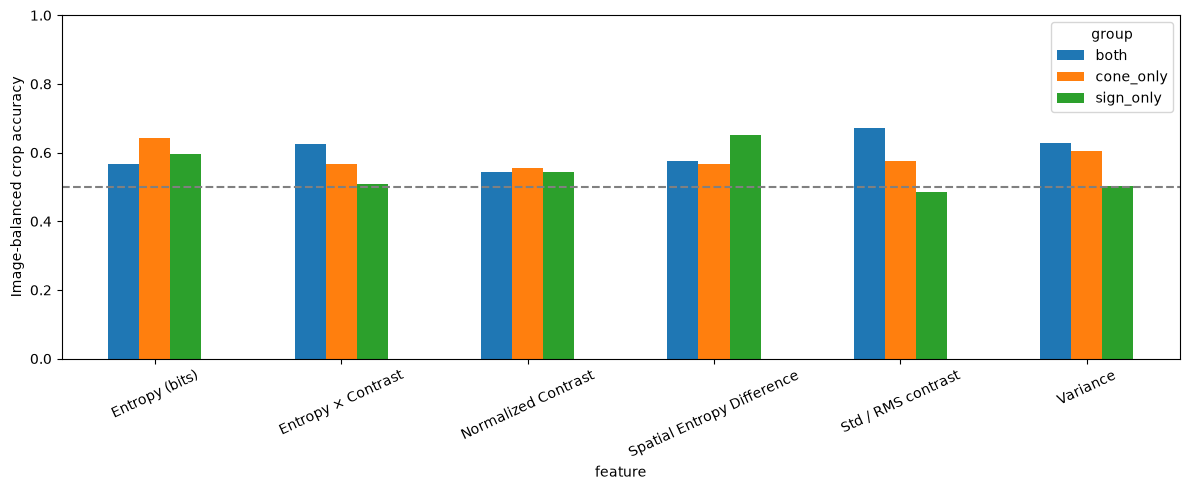

,group,feature,raw_auc,direction_selected_auc,histogram_overlap
1,cone_only,Variance,0.6481,0.6481,0.6708
2,cone_only,Std / RMS contrast,0.6481,0.6481,0.6579
6,cone_only,Entropy (bits),0.6545,0.6545,0.6242
8,cone_only,Entropy × Contrast,0.6593,0.6593,0.6750
9,cone_only,Normalized Contrast,0.5990,0.5990,0.6833
10,cone_only,Spatial Entropy Difference,0.3625,0.6375,0.7067
12,sign_only,Variance,0.5106,0.5106,0.7031
13,sign_only,Std / RMS contrast,0.5106,0.5106,0.7375
17,sign_only,Entropy (bits),0.6061,0.6061,0.7938
19,sign_only,Entropy × Contrast,0.5381,0.5381,0.7000


In [4]:
features=['Entropy (bits)','Variance','Std / RMS contrast','Entropy × Contrast','Normalized Contrast','Spatial Entropy Difference']
table=crop[crop.feature.isin(features)].pivot(index='feature',columns='group',values='balanced_accuracy')
display(table.round(4))
table.plot.bar(figsize=(12,5),ylim=(0,1),rot=25)
plt.axhline(.5,color='gray',linestyle='--');plt.ylabel('Image-balanced crop accuracy');plt.tight_layout();plt.show()
display(separation[separation.feature.isin(features)].round(4))


## Full-image detection

Near-zero values are shown numerically; small changes do not make a usable detector. Negative-group FP counts are included separately.

In [5]:
display(detection[detection.scope=='all'].round(6))
display(detection[detection.scope=='negative'][['feature','fp']])
display(speed.round(4))


,feature,scope,tp,fp,fn,precision,recall,f1
0,histogram,all,5,19631,223,0.000255,0.021930,0.000503
7,entropy,all,0,2,228,0.000000,0.000000,0.000000
14,entropy_contrast,all,0,0,228,0.000000,0.000000,0.000000
21,normalized_contrast,all,2,4798,226,0.000417,0.008772,0.000796
28,spatial_entropy_difference,all,1,5100,227,0.000196,0.004386,0.000375


,feature,fp
4,histogram,3280
11,entropy,0
18,entropy_contrast,0
25,normalized_contrast,702
32,spatial_entropy_difference,874


,feature,seconds_per_image
0,histogram,0.1522
1,entropy,0.1571
2,entropy_contrast,0.2874
3,normalized_contrast,0.2877
4,spatial_entropy_difference,0.2876


## Decision

There is no universal crop-level winner, and none of these engineered features fixes the current average-template detector. Preserve this experiment. Prioritize testing template-bank matching and proposal survival before adding more formulas. Spatial entropy remains a sign-crop hypothesis, not an established detection improvement.

## Candidate-loss diagnosis

Coverage is independent per source box, not one-to-one detector recall. The average-template path covers 180 source boxes initially, 29 after ranking top1000, 16 after full NMS, and 6 after max100 output cap. The final one-to-one TP count is 5. The representative 8-template bank and top10000 alternatives did not improve F1.

In [6]:
display(saved_csv('survival_summary.csv'))
display(saved_csv('diagnostic_metrics.csv').query("scope=='all'").round(6))

,method,stage,covered,gt,coverage
0,average_top1000,all_windows,180,228,0.789474
1,average_top1000,post_nms_before_cap,16,228,0.070175
2,average_top1000,post_nms_cap100,6,228,0.026316
3,average_top1000,post_threshold,6,228,0.026316
4,average_top1000,top1000,29,228,0.127193
5,average_top10000,all_windows,180,228,0.789474
6,average_top10000,post_nms_cap100,6,228,0.026316
7,average_top10000,post_threshold,6,228,0.026316
8,average_top10000,top10000,109,228,0.478070
9,bank8_top1000,all_windows,180,228,0.789474


,method,scope,tp,fp,fn,precision,recall,f1
0,average_top1000,all,5,19631,223,0.000255,0.02193,0.000503
7,average_top10000,all,5,19631,223,0.000255,0.02193,0.000503
14,bank8_top1000,all,0,0,228,0.000000,0.00000,0.000000
21,bank8_top10000,all,0,0,228,0.000000,0.00000,0.000000


## Recommended next step

Keep the existing window geometry as a baseline. Test target-versus-background scoring to improve ranking, and measure NMS/output-cap sensitivity. Do not conclude more templates, more features or smaller strides will automatically help. See notebook 04 for the exact controlled diagnosis. This notebook shows the bundled snapshot; new reruns in 01/02/04 do not automatically replace this saved snapshot.
